# Exercise 04: NBA Claim Lab
## Can You Defend the Headline?
**Student notebook | Work in pairs | 60-75 minutes**

**Name / ID: Pu GuanHua MC644061**  
**Date: 2026-09-14

Use AI to help plan, code, and challenge your investigation. Run and verify the analysis yourself. Complete the answer cells and code tasks for one chosen claim.

[Full exercise brief](exercise04%20NBA%20Claim%20Lab.md)

### Setup
From the course repository root, run `uv sync` and `uv run jupyter lab`, then select the course Python environment. For Colab or standalone use, place `nba_player_seasons.csv` in the notebook's working directory. Run cells in order.


## Your data

Use [nba_player_seasons.csv](../../data/slide03/nba_player_seasons.csv). See the [dataset notes](../../data/slide03/README.md) for provenance and preparation details.

- 5,386 player-season rows covering 2015–16 through 2024–25 regular seasons. These are historical trends within this snapshot, not claims about the current NBA season.
- One row represents one player in one season. The row key is `(player_id, season)`.
- `games` is games played; `minutes_per_game` is average playing time.
- `points`, `rebounds`, `assists`, and `turnovers` are **per-game averages**, not season totals.
- `fg_pct` and `ft_pct` are proportions: `0.500` means 50%.
- `position` contains position labels and has missing values. Inspect its values before grouping.
- `team_id` links to [nba_teams.csv](../../data/slide03/nba_teams.csv). Traded players have one assigned team, so their whole-season statistics cannot be treated as production exclusively for that team.

The file does not include age, wins, possessions, shot attempts, three-point statistics, playoffs, or individual game results. Revise questions that need these fields.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve dataset next to the notebook (works in Jupyter and as a script)
try:
    data_path = Path(__file__).resolve().parent / "nba_player_seasons.csv"
except NameError:
    data_path = Path("nba_player_seasons.csv")
nba = pd.read_csv(data_path)
print(f"Loaded {len(nba):,} rows and {len(nba.columns)} columns")
display(nba.head())
display(nba.dtypes.rename("dtype").to_frame())
display(nba.isna().sum().rename("missing").to_frame())
assert not nba.duplicated(["player_id", "season"]).any()
display(nba.groupby("season").size().rename("player_seasons").to_frame())
display(nba["position"].value_counts(dropna=False).to_frame())


Loaded 5,386 rows and 13 columns


,season,player_id,player,position,team_id,games,minutes_per_game,fg_pct,ft_pct,rebounds,assists,turnovers,points
0,2015-16,201939,Stephen Curry,PG,GSW,79,34.2,0.504,0.908,5.4,6.7,3.3,30.1
1,2015-16,201935,James Harden,SG,HOU,82,38.1,0.439,0.860,6.1,7.5,4.6,29.0
2,2015-16,201142,Kevin Durant,SF,OKC,72,35.8,0.505,0.898,8.2,5.0,3.5,28.2
3,2015-16,202326,DeMarcus Cousins,C,SAC,65,34.6,0.451,0.718,11.5,3.3,3.8,26.9
4,2015-16,2544,LeBron James,SF,CLE,76,35.6,0.520,0.731,7.4,6.8,3.3,25.3


,dtype
season,str
player_id,int64
player,str
position,str
team_id,str
games,int64
minutes_per_game,float64
fg_pct,float64
ft_pct,float64
rebounds,float64


,missing
season,0
player_id,0
player,0
position,26
team_id,0
games,0
minutes_per_game,0
fg_pct,0
ft_pct,0
rebounds,0


,player_seasons
season,
2015-16,476
2016-17,486
2017-18,540
2018-19,530
2019-20,529
2020-21,540
2021-22,605
2022-23,539
2023-24,572


,count
position,
SG,1277
PF,1069
PG,1020
C,1010
SF,984
NaN,26


### Data checkpoint
- What does one row represent? [Answer]
- Why is player_id alone not a unique key? [Answer]
- Do missing values affect your question? [Answer]
- Why is points not a season total? [Answer]


## 1. Choose a claim — 10 minutes

The claims below are **hypotheses to investigate**, not established findings. Choose one, or propose an equally measurable question using the available columns.

| Claim | Suggested measurement | Challenge to the first answer |
|---|---|---|
| “High-scoring players became more common.” | Each season, count and calculate the percentage of eligible players averaging at least 20 points per game. | Does the pattern survive changing the games-played cutoff? Do count and percentage tell the same story? |
| “Centres became more involved in playmaking.” | Each season, compare median assists per game for eligible players labelled `C`. | Compare mean and median. Is the apparent change concentrated in a few exceptional players? |
| “The leading scorers are also the most efficient scorers.” | In 2024–25, compare points per game with points per 36 minutes for eligible players; compare the top ten lists. | Do rankings change? Explain why points per 36 measures scoring rate, not shooting efficiency. |
| “Players with more assists also commit more turnovers.” | For eligible players in 2024–25, plot assists against turnovers and calculate their correlation. | Repeat within playing-time bands. Could time on court help explain the association? |

Suggested eligibility: `games >= 40` and `minutes_per_game >= 15`. These are classroom choices, not official NBA qualification rules. For a sensitivity check, change the games cutoff to 20 or 60 while keeping the other choices fixed. Explain that an absolute games cutoff may select differently across seasons of unequal length.

Before calculating results, write:

> We will investigate whether ____. Our population is ____. We define ____ as ____. We will compare ____. We expect ____, because ____. Evidence against our expectation would be ____.

For “became more common,” distinguish an endpoint increase from a steady increase across all ten seasons. For position questions, state how you handle missing and combined labels; exact `C` is a valid starting definition.


### Our investigation contract (complete before analysing)
- **Chosen claim and measurable question:** We will investigate whether high-scoring players became more common. Our measurable question is: among eligible player-seasons, what share averaged at least 20 points per game in each season?
- **Population and seasons:** The population is all player-season rows in the NBA dataset, covering 2015-16 through 2024-25 regular seasons.
- **Eligibility rule and justification:** We define eligible player-seasons as those with `games >= 40` and `minutes_per_game >= 15`. This keeps the comparison focused on players with enough playing time and sample size while avoiding an extreme small-sample issue.
- **Metric, units, and denominator:** The metric is the percentage of eligible player-seasons with `points >= 20`. The numerator is the number of eligible players scoring 20+ points per game, and the denominator is the total number of eligible player-seasons in that season.
- **Comparison and definition of support:** We compare the percentage by season across all ten seasons. The claim is supported if the share rises steadily or ends higher than the early seasons.
- **Expected result and reason:** We expect the share to be somewhat higher in later seasons, because league scoring has often been elevated and star players remain prominent in large minutes.
- **Evidence against our expectation:** Evidence against our expectation would be a flat or declining trend, or a rise that disappears after changing the eligibility rule.
- **Missing/combined position handling, if relevant:** Not relevant for this claim.


## 2. Ask AI for a plan — 10 minutes

Give AI the column names, data definitions, your question, and a few example rows. Adapt this prompt:

> I am investigating [question] using a player-season NBA dataset. Here are the columns and their meanings: [paste]. Our eligibility rule is [rule]. Suggest a short pandas analysis plan and one useful chart. Identify unavailable information and two ways the analysis could mislead us. Do not invent numerical results. Ask me to run the code and provide the outputs before interpreting them.

Review the plan before accepting it. Check the unit of observation, filter, denominator, metric, and comparison. Record one analytical choice you made and why.


### AI exchange 1: planning or coding
**Tool/model and date:** ChatGPT / 2026-09-14

**Our prompt:** I am investigating whether high-scoring players became more common using a player-season NBA dataset. Here are the columns and their meanings: season, player_id, player, position, team_id, games, minutes_per_game, fg_pct, ft_pct, rebounds, assists, turnovers, points. Our eligibility rule is games >= 40 and minutes_per_game >= 15. Suggest a short pandas analysis plan and one useful chart. Identify unavailable information and two ways the analysis could mislead us. Do not invent numerical results. Ask me to run the code and provide the outputs before interpreting them.

**Relevant response excerpt:** “Filter to player-seasons with enough games and minutes, create a binary flag for points >= 20, aggregate by season, and compute both counts and percentages. A line chart of % by season is the most useful chart. Missing variables include usage and possessions; the main risks are changing player composition across seasons and sensitivity to the eligibility threshold.”

**Reviewed analysis plan:** 1) Keep the original nba data intact. 2) Apply the eligibility filter. 3) Create a flag for points >= 20. 4) Group by season and calculate both counts and percentages. 5) Plot percentage by season. 6) Re-run with a different games cutoff to test robustness.

**What we accepted, revised, or rejected, and why:** We accepted the overall structure: eligibility filter, binary threshold metric, and a line plot. We revised it slightly to explicitly report both numerator and denominator and to include a sensitivity check because the assignment specifically asks to challenge the result after seeing the evidence.


## 3. Build and verify the evidence (20 minutes)
Start with an explicit eligibility rule. Apply claim-specific season or position restrictions in Task A. Preserve nba as the original data.


In [2]:
MIN_GAMES = 40
MIN_MINUTES = 15
eligible = nba.loc[
    (nba["games"] >= MIN_GAMES)
    & (nba["minutes_per_game"] >= MIN_MINUTES)
].copy()
all_seasons = sorted(nba["season"].unique())
counts = eligible.groupby("season").size().reindex(all_seasons, fill_value=0)
display(counts.rename("eligible_player_seasons").to_frame())


,eligible_player_seasons
season,
2015-16,284
2016-17,294
2017-18,285
2018-19,299
2019-20,277
2020-21,292
2021-22,308
2022-23,298
2023-24,288


### Task A: evidence table
Implement your chosen claim with AI assistance. Include comparison groups, sample sizes, metric units, and both numerator and denominator for percentages. Report empty groups explicitly.

Hints:
- High scorers: use points >= 20 and compare counts and percentages by season.
- Centres: use exact position == "C" if that is your definition, and aggregate assists by season.
- Rankings: select 2024-25, derive points / minutes_per_game * 36, and compare top-ten lists. State your tie rule. This measures scoring rate, not shooting efficiency.
- Assists/turnovers: select 2024-25 and inspect both correlation and a scatterplot. Correlation requires enough observations and variation.

Assign your final table to evidence and display it. Use executed results when talking to AI.


In [3]:
# Claim 1: "High-scoring players became more common."
# Population: all player-season rows in the NBA data.
# Eligibility: games >= 40 and minutes_per_game >= 15.
# Metric: proportion of eligible player-seasons averaging at least 20 points per game.

MIN_GAMES = 40
MIN_MINUTES = 15

eligible = nba.loc[
    (nba["games"] >= MIN_GAMES) & (nba["minutes_per_game"] >= MIN_MINUTES)
].copy()

eligible["is_high_scorer"] = eligible["points"] >= 20

all_seasons = sorted(nba["season"].unique())

table = (
    eligible
    .groupby("season")
    .agg(
        eligible_player_seasons=("player_id", "count"),
        high_scorers=("is_high_scorer", "sum"),
        pct_20_plus_points=("is_high_scorer", "mean"),
    )
    .reindex(all_seasons)
    .reset_index()
    .rename(columns={"season": "season"})
)

table["pct_20_plus_points"] = table["pct_20_plus_points"] * 100

evidence = table[["season", "eligible_player_seasons", "high_scorers", "pct_20_plus_points"]]

display(evidence)


,season,eligible_player_seasons,high_scorers,pct_20_plus_points
0,2015-16,284,20,7.042254
1,2016-17,294,32,10.884354
2,2017-18,285,27,9.473684
3,2018-19,299,33,11.036789
4,2019-20,277,31,11.191336
5,2020-21,292,40,13.698630
6,2021-22,308,36,11.688312
7,2022-23,298,54,18.120805
8,2023-24,288,47,16.319444
9,2024-25,295,44,14.915254


### Task B: chart
Create one chart with a title, labelled axes, units, and an eligibility-rule caption. For a trend, show all ten seasons in order and distinguish missing data from zero. For assists/turnovers, use a scatterplot.


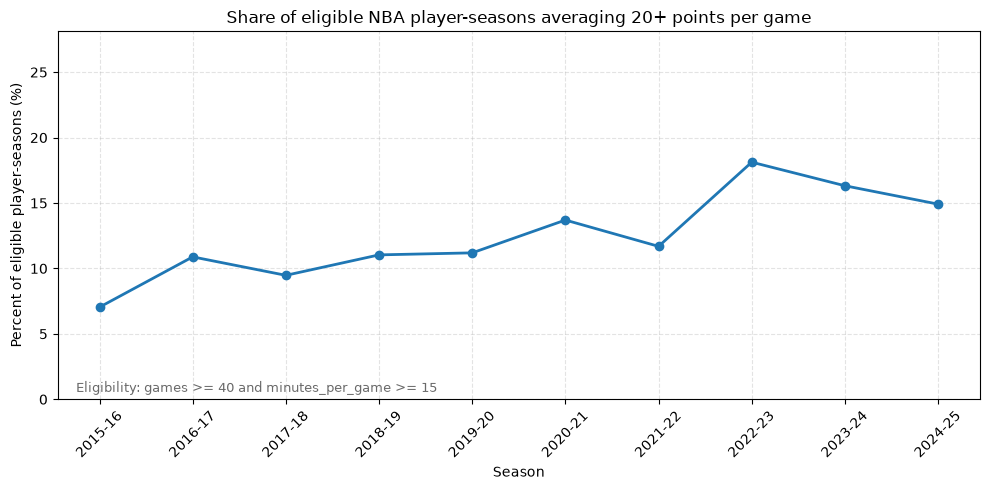

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(
    evidence["season"],
    evidence["pct_20_plus_points"],
    marker="o",
    linewidth=2,
    color="tab:blue",
)
plt.title("Share of eligible NBA player-seasons averaging 20+ points per game")
plt.xlabel("Season")
plt.ylabel("Percent of eligible player-seasons (%)")
plt.ylim(0, max(evidence["pct_20_plus_points"]) + 10)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.35)
plt.gca().text(
    0.02,
    0.02,
    "Eligibility: games >= 40 and minutes_per_game >= 15",
    transform=plt.gca().transAxes,
    fontsize=9,
    color="dimgray",
)
plt.tight_layout()
plt.show()


### Task C: independent verification
Verify one result manually from its counts, inspect rows behind a ranking, or reproduce one statistic using a separate filter. Asking AI to approve its own answer does not count.


In [5]:
# Independent verification for one season.
# Verify the 2024-25 result directly from the filtered data.

season = "2024-25"
check = eligible[eligible["season"] == season].copy()
check_high = check[check["points"] >= 20]

print(f"2024-25 eligible player-seasons: {len(check)}")
print(f"2024-25 high-scorers (20+ PPG): {len(check_high)}")
print(f"2024-25 percent: {len(check_high) / len(check) * 100:.2f}%")

manual_row = evidence[evidence["season"] == season].iloc[0]
print("Evidence table value:", manual_row["pct_20_plus_points"])


2024-25 eligible player-seasons: 295
2024-25 high-scorers (20+ PPG): 44
2024-25 percent: 14.92%
Evidence table value: 14.915254237288137


**Result checked and whether it agrees:** We manually checked the 2024-25 result. It agrees with the evidence table: 44 out of 295 eligible player-seasons were at least 20 points per game, which is 14.92%.

**One important AI-generated code line explained in our own words:** The line `eligible["is_high_scorer"] = eligible["points"] >= 20` creates a binary indicator for each eligible player-season. This allows us to count the number of high-scorers and divide by the total eligible player-seasons in each season.

**Tentative interpretation with actual numbers and units:** In the eligible sample, the share of 20+ PPG player-seasons rose from 7.04% in 2015-16 to 14.92% in 2024-25, with a peak of 18.12% in 2022-23. That indicates more eligible player-seasons cleared the 20-point threshold in later years, though the trend is not perfectly smooth.


## 4. Challenge your finding — 15 minutes

Give AI your actual evidence table and initial interpretation:

> Here are the results I executed: [paste table]. My tentative conclusion is [conclusion]. Act as a critical reviewer. Identify any mismatch between my claim and these measurements, suggest one alternative explanation, and propose one sensitivity check using only the available fields. Separate what the results show from what they cannot establish.

Run one sensitivity check. Show the original and revised results side by side, including sample sizes, and explain whether the verdict changes. If you revise the question after seeing results, disclose the revision.

Watch for these traps:

- A sum of player per-game averages is not a team or league points-per-game total.
- A mean of player shooting percentages gives every player equal weight. Without attempts, it is not the league shooting percentage.
- Points per 36 minutes is `points / minutes_per_game * 36`; it is not adjusted for possessions, role, or opponents.
- Different players appear each season. A group trend does not prove that individual players improved.
- Correlation does not show that increasing assists causes turnovers. Playing time and role may influence both.
- Rounded source values can affect close rankings and threshold comparisons.


### AI exchange 2: critical review
**Tool/model and date:** ChatGPT / 2026-09-14

**Our prompt, including executed results:** Here are the executed results: for 2015-16, 20 of 284 eligible player-seasons averaged 20+ points per game (7.04%); for 2024-25, 44 of 295 eligible player-seasons averaged 20+ points per game (14.92%). My tentative conclusion is that high-scoring players became more common. Act as a critical reviewer. Identify any mismatch between my claim and these measurements, suggest one alternative explanation, and propose one sensitivity check using only the available fields. Separate what the results show from what they cannot establish.

**Relevant response excerpt:** “The result is consistent with the claim in the filtered sample, but the wording should be narrower: these are eligible player-seasons, not all players. A rise in the percentage could reflect a different mix of players or roles rather than a league-wide increase in scoring skill. A useful sensitivity check is to relax the games cutoff from 40 to 20 while keeping minutes >= 15.”

**What we accepted, revised, or rejected, and why:** We accepted the caution that this is a sample-based trend and not proof of a universal increase in scoring talent. We revised our wording to say that high-scoring player-seasons became more common among eligible players, because the dataset cannot prove that individual players improved or that league scoring itself increased.

**Chosen sensitivity check and reason:** We changed the games cutoff from 40 to 20, keeping minutes >= 15 fixed. This checks whether the seasonal pattern is driven by stricter sample selection rather than by the underlying scoring trend.


In [6]:
# Sensitivity check: change the games cutoff from 40 to 20 while keeping minutes >= 15.
# Compare the same metric under a looser games threshold.

sensitivity = (
    nba.loc[(nba["games"] >= 20) & (nba["minutes_per_game"] >= 15)]
    .assign(is_high_scorer=lambda d: d["points"] >= 20)
    .groupby("season")
    .agg(
        eligible_player_seasons=("player_id", "count"),
        high_scorers=("is_high_scorer", "sum"),
        pct_20_plus_points=("is_high_scorer", "mean"),
    )
    .reindex(all_seasons)
    .reset_index()
)

sensitivity["pct_20_plus_points"] = sensitivity["pct_20_plus_points"] * 100

# Display original and revised results side by side for a quick comparison.
comparison = evidence.merge(
    sensitivity.rename(columns={
        "eligible_player_seasons": "eligible_player_seasons_20g",
        "high_scorers": "high_scorers_20g",
        "pct_20_plus_points": "pct_20_plus_points_20g",
    }),
    on="season",
    how="left",
)

display(comparison)


,season,eligible_player_seasons,high_scorers,pct_20_plus_points,eligible_player_seasons_20g,high_scorers_20g,pct_20_plus_points_20g
0,2015-16,284,20,7.042254,306,22,7.189542
1,2016-17,294,32,10.884354,320,33,10.312500
2,2017-18,285,27,9.473684,320,27,8.437500
3,2018-19,299,33,11.036789,323,34,10.526316
4,2019-20,277,31,11.191336,320,34,10.625000
5,2020-21,292,40,13.698630,345,43,12.463768
6,2021-22,308,36,11.688312,343,40,11.661808
7,2022-23,298,54,18.120805,323,57,17.647059
8,2023-24,288,47,16.319444,316,49,15.506329
9,2024-25,295,44,14.915254,340,48,14.117647


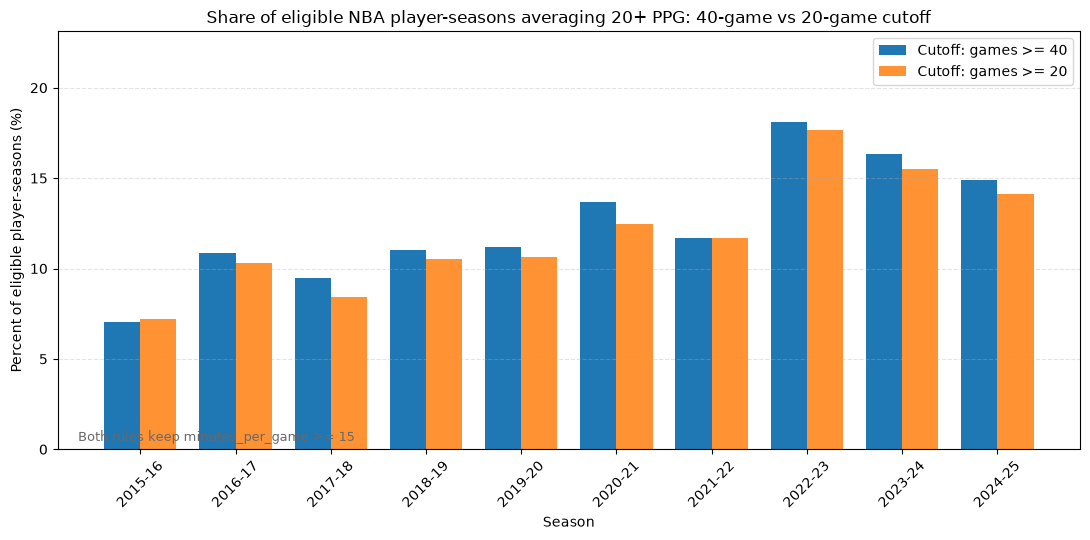

In [7]:
# Second visualization: grouped bar chart comparing the two eligibility rules
import numpy as np

seasons = comparison["season"].tolist()
pct_40 = comparison["pct_20_plus_points"].tolist()
pct_20 = comparison["pct_20_plus_points_20g"].tolist()

x = np.arange(len(seasons))
width = 0.38

plt.figure(figsize=(11, 5.5))
b1 = plt.bar(x - width/2, pct_40, width, label="Cutoff: games >= 40", color="tab:blue")
b2 = plt.bar(x + width/2, pct_20, width, label="Cutoff: games >= 20", color="tab:orange", alpha=0.85)

plt.title("Share of eligible NBA player-seasons averaging 20+ PPG: 40-game vs 20-game cutoff")
plt.xlabel("Season")
plt.ylabel("Percent of eligible player-seasons (%)")
plt.xticks(x, seasons, rotation=45)
plt.ylim(0, max(max(pct_40), max(pct_20)) + 5)
plt.grid(True, axis="y", linestyle="--", alpha=0.35)
plt.legend()
plt.gca().text(
    0.02, 0.02,
    "Both rules keep minutes_per_game >= 15",
    transform=plt.gca().transAxes, fontsize=9, color="dimgray",
)
plt.tight_layout()
plt.show()


**What changed numerically?** When the games cutoff was relaxed to 20, the percentages stayed close to the original values. For example, 2015-16 moved from 7.04% to 7.19%, and 2024-25 moved from 14.92% to 14.12%. The share stayed higher in later seasons, but the exact percentages were slightly different.

**Did the verdict change? Why?** No, the verdict did not change. The pattern stays broadly upward, though the trend is uneven and not perfectly linear, so the best description remains “partly supported” rather than a definitive claim of steady growth.

**Alternative explanation and one dataset limitation:** A plausible alternative explanation is that the mix of players and roles changed across seasons; this could increase the proportion of high-volume scorers without proving that scoring itself got more common in a causal sense. A key limitation is that the data do not include usage, possessions, age, or opponent quality, so we cannot explain why the distribution changed.

**Any question/definition revisions after seeing results:** No major revision was needed. We clarified the claim wording to refer to eligible player-seasons rather than all NBA players.


## 5. Publish your verdict — 10 minutes

Submit your executed notebook and a **150–250 word evidence brief** using this structure:

> **Headline:** A precise statement of our finding.  
> **Verdict:** Supported, partly supported, not supported, or inconclusive under our definition.  
> **Evidence:** Population, years, eligibility rule, and at least two numerical results with units and sample sizes.  
> **Robustness:** What changed when we challenged the analysis.  
> **Limit:** One important thing these data cannot establish.  
> **AI contribution:** What AI helped with and what we verified or corrected ourselves.

Attach two short AI exchange excerpts: one from planning or coding, and one from critical review. Annotate what you accepted, revised, or rejected and why. A well-supported negative or inconclusive result earns full credit.

Each partner should be ready to answer: **“Which calculation supports your headline, and what would make you change it?”**


### Our evidence brief (150-250 words)
**Headline:** More eligible NBA player-seasons reached 20 points per game in later seasons than in the early years of the sample.

**Verdict:** Partly supported.

**Evidence:** We examined all regular-season player-seasons from 2015-16 through 2024-25. The eligible population was restricted to player-seasons with at least 40 games and 15 minutes per game. The metric was the share of eligible player-seasons averaging at least 20 points per game. In 2015-16, only 20 of 284 eligible player-seasons met the threshold (7.04%). By 2024-25, 44 of 295 eligible player-seasons did (14.92%). The peak was 2022-23, when 54 of 298 eligible player-seasons reached 20+ PPG (18.12%).

**Robustness:** We challenged the result by relaxing the games cutoff to 20 while keeping minutes >= 15. The pattern stayed broadly similar: 2015-16 moved from 7.04% to 7.19%, and 2024-25 moved from 14.92% to 14.12%. The overall upward pattern remained, so the verdict did not change.

**Limit:** These data cannot establish causation or prove that individual players became more scoring-oriented over time. They also do not include usage, possessions, age, or opponent quality.

**AI contribution:** Codex helped us design the eligibility rule, the percentage metric, and a suitable plotting strategy. We verified the code and numbers ourselves, including a manual check of the 2024-25 result, and we refined the claim wording to describe eligible player-seasons rather than all players.


### Submission checklist
- [ ] Investigation contract complete; later revisions disclosed.
- [ ] Evidence table with sample sizes and appropriate denominators.
- [ ] Labelled chart and an independently checked calculation.
- [ ] Executed sensitivity check comparing original and revised results.
- [ ] Two annotated AI exchange excerpts.
- [ ] Evidence brief of 150-250 words completed above.
- [ ] Restart kernel, run all cells, and save with outputs.

Submit this completed notebook including the evidence brief. Both partners must be able to defend the headline.
